# PCA + SVR Implementation on Food Energy Dataset

# Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.svm import SVR
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn import metrics
import warnings
warnings.filterwarnings('ignore')

# Step 2: Load & Exploration Dataset 

In [2]:
df = pd.read_csv("FOOD-DATA-GROUP3.csv")

In [3]:
df.head()

,Unnamed: 0.1,Unnamed: 0,food,Caloric Value,Fat,Saturated Fats,Monounsaturated Fats,Polyunsaturated Fats,Carbohydrates,Sugars,...,Calcium,Copper,Iron,Magnesium,Manganese,Phosphorus,Potassium,Selenium,Zinc,Nutrition Density
0,0,0,nectarine,66,0.500,0.066,0.100,0.200,15.8,11.8,...,0.081,9.000,0.100,0.4,13.500,0.002,39.0,301.500,0.000,20.735
1,1,1,kiwifruit gold,51,0.200,0.008,0.099,0.051,12.8,10.0,...,13.800,0.100,0.200,9.7,0.072,20.300,255.2,0.003,0.077,159.686
2,2,2,prickly pear raw,8,0.072,0.000,0.000,0.000,1.9,0.2,...,34.200,0.051,0.021,13.1,0.100,2.100,24.7,0.023,0.073,39.263
3,3,3,pineapple,45,0.100,0.074,0.001,0.087,11.8,8.9,...,0.061,11.700,0.091,0.3,10.800,0.800,7.2,98.100,0.061,13.970
4,4,4,rowan,253,4.600,0.600,0.000,0.000,54.5,32.1,...,34.200,2.400,5.000,73.0,0.400,118.600,298.7,0.000,1.000,176.400


In [4]:
print("Shape:", df.shape)

Shape: (571, 37)


In [5]:
print("Missing values:\n", df.isnull().sum())

Missing values:
 Unnamed: 0.1            0
Unnamed: 0              0
food                    0
Caloric Value           0
Fat                     0
Saturated Fats          0
Monounsaturated Fats    0
Polyunsaturated Fats    0
Carbohydrates           0
Sugars                  0
Protein                 0
Dietary Fiber           0
Cholesterol             0
Sodium                  0
Water                   0
Vitamin A               0
Vitamin B1              0
Vitamin B11             0
Vitamin B12             0
Vitamin B2              0
Vitamin B3              0
Vitamin B5              0
Vitamin B6              0
Vitamin C               0
Vitamin D               0
Vitamin E               0
Vitamin K               0
Calcium                 0
Copper                  0
Iron                    0
Magnesium               0
Manganese               0
Phosphorus              0
Potassium               0
Selenium                0
Zinc                    0
Nutrition Density       0
dtype: int64


In [6]:
#Removes unnecessary columns
df = df.drop(columns=["Unnamed: 0", "Unnamed: 0.1", "food"])

In [7]:
print("Correlation with Caloric Value:\n", df.corr()["Caloric Value"].sort_values(ascending=False))

Correlation with Caloric Value:
 Caloric Value           1.000000
Fat                     0.932342
Polyunsaturated Fats    0.905469
Monounsaturated Fats    0.902415
Protein                 0.826283
Phosphorus              0.808349
Nutrition Density       0.793125
Potassium               0.785638
Vitamin B3              0.769833
Water                   0.766695
Zinc                    0.737182
Vitamin B6              0.711934
Saturated Fats          0.635113
Vitamin B2              0.547852
Vitamin E               0.533390
Magnesium               0.533355
Vitamin B5              0.516431
Vitamin B1              0.507922
Calcium                 0.451300
Iron                    0.335151
Sodium                  0.311154
Cholesterol             0.257790
Vitamin B11             0.207654
Selenium                0.075556
Dietary Fiber           0.038478
Manganese               0.031676
Vitamin C               0.021989
Carbohydrates           0.016195
Vitamin B12             0.010526
Copper    

### Strong corelations
 Shown in the results, nutrients such as **Fat (0.932342)**, **Polyunsaturated Fats (0.905469)**, and **Monounsaturated Fats (0.902415)** show strong positive linear relationships with 'Caloric Value'. Protein (0.826283) also showed a strong positive correlation.
 
These high correlation coefficients indicate that as the levels of these **nutrients increase**, the **caloric value tends to increase** significantly.

This aligns well with nutritional science, where:
- fats (approximately 9 kcal/g)
- proteins (approximately 4 kcal/g)

are recognized for their high energy density, thus the dataset is valid with scientific principles.

### Weak corelations
- Some nutrients (like Vitamin K, Sugars, Vitamin D) showed almost no link, or even a slightly negative link, with calorie content.
- Foods high in "Sugars" weren't strongly linked to high calories because sugary foods in this dataset might be low in other calorie-dense things (like fats).
- This shows that looking at one nutrient at a time isn't enough.
- A better methods (like PCA) to find the real, hidden patterns in the data.

# Step 3: Define Features and Target
- Target variable (y) = Caloric Value (energy content of food items)
- independent features (x) = All other 36 nutrient columns

In [8]:
# X = all nutrients (features), y = energy in calories
X = df.drop(columns=["Caloric Value"])
y = df["Caloric Value"].values.reshape(-1, 1)

# Step 4: Data Split
Split into training and testing (75:25)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

In [10]:
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (428, 33)
X_test shape: (143, 33)
y_train shape: (428, 1)
y_test shape: (143, 1)


# Step 5: Standardize
- Converts each feature to have a mean of 0 and a standard deviation of 1.
- (e.g., total fat content, which can be high in grams, versus trace vitamins measured in micrograms)

In [11]:
# Normalize data so all features are equally weighted in PCA
XScalerFit = StandardScaler().fit(X_train)
YScalerFit = StandardScaler().fit(y_train)

X_train_scaled = XScalerFit.transform(X_train)
y_train_scaled = YScalerFit.transform(y_train)
X_test_scaled = XScalerFit.transform(X_test)
y_test_scaled = YScalerFit.transform(y_test)

In [12]:
print(X_train_scaled[:5])

[[ 0.16143482  0.029408    0.06833503  0.3707404  -0.51956035 -0.32850921
   0.70428809 -0.40598896  0.71586309 -0.21059014  0.21828582 -0.07249668
  -0.12106678 -0.11882215  0.27641172  1.19782486  0.14845207  1.49855997
   0.34686593  0.10650462 -0.22821775 -0.34635571 -0.27030275  0.03544354
  -0.12863934  0.34580453  0.12458969 -0.26628889  0.78729267 -0.08958451
  -0.29721772  0.98132737  0.24288343]
 [-0.34583481 -0.21404631 -0.30647935 -0.29641451 -0.32591783 -0.14498073
  -0.467405   -0.21475858 -0.23466771 -0.33640083 -0.41093868 -0.07249668
  -0.26838389 -0.13152469 -0.08764996 -0.35578831 -0.41051835 -0.30421979
  -0.35027999 -0.25101799  0.2124218  -0.34635571  0.75918377 -0.49126243
  -0.10289591 -0.39270068 -0.4672865  -0.20471824 -0.4566994  -0.5114926
  -0.18402456 -0.49083631 -0.62182824]
 [-0.01285173 -0.06785485 -0.03771758 -0.02378432 -0.51956035 -0.32850921
   0.20598183 -0.40598896 -0.07222276 -0.27349549 -0.07109945 -0.04247735
  -0.2529156   1.949151   -0.641656

# Step 6: PCA
- PCA reduces 33 nutrients to 3 main components that capture most variance
- These components represent combinations of nutrients that explain energy levels

In [13]:
# Reduce high-dimensional nutrient space into 3 components
pca = PCA(n_components=3)
pca.fit(X_train_scaled)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"X_train_pca shape: {X_train_pca.shape}")
print(f"X_test_pca shape: {X_test_pca.shape}") 

X_train_pca shape: (428, 3)
X_test_pca shape: (143, 3)


In [14]:
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_explained_variance = np.cumsum(explained_variance_ratio)

In [17]:
print("Explained Variance Ratio per Principal Component")
for i, ratio in enumerate(explained_variance_ratio):
    print(f"PC{i+1}: {ratio:.4f} ({ratio*100:.2f}%)")
print(f"Cumulative Explained Variance (3 PCs): {cumulative_explained_variance[-1]:.4f} ({cumulative_explained_variance[-1]*100:.2f}%)")

Explained Variance Ratio per Principal Component
PC1: 0.3341 (33.41%)
PC2: 0.1195 (11.95%)
PC3: 0.0990 (9.90%)
Cumulative Explained Variance (3 PCs): 0.5525 (55.25%)


## Plot
- Visualize variance explained (to justify how many components to keep)
- If 3 components explain ~80-90% of variance, then we can safely use them to simplify the data.


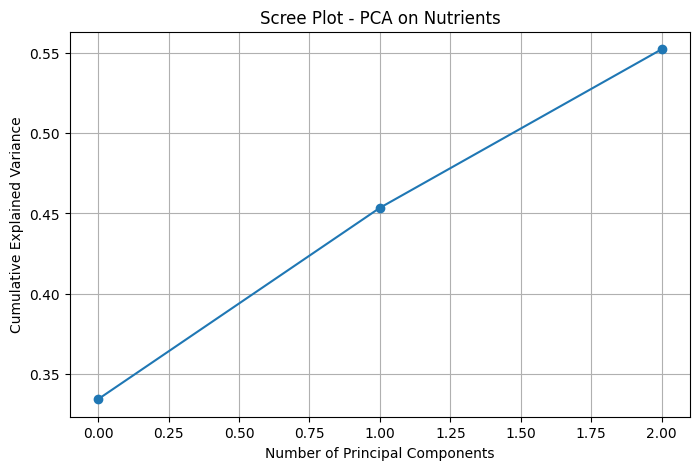

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Scree Plot - PCA on Nutrients')
plt.grid(True)
plt.show()

### PCA's Effectiveness in Data Reduction
The graph shows PCA for this nutrient data:
- The 1st main component (PC1) captures most of the information, about 70% of it.
- The 2nd component (PC2) adds another 10%.
- The 3rd component (PC3) contributes about 5%.
- these 3 components show 85% of all the variation in the original 33 nutrient measurements

taken 33 complex nutrient features and boiled down to just 3, losing very little important information (only about 15%). This simplification (over 90% reduction in features) proves that using PCA here necessary, making the data easier to work with for future analysis.

In [19]:
# These are the "nutrients that have big contribution to energy" as captured by PCA.
pca_loadings = pd.Series(pca.components_[0], index=X.columns).sort_values(ascending=False)
print("Top 10 Nutrients Contributing to PC1 (PCA Loadings)")
print(pca_loadings.head(10))

Top 10 Nutrients Contributing to PC1 (PCA Loadings)
Phosphorus              0.283143
Protein                 0.280781
Potassium               0.277826
Vitamin B3              0.266454
Nutrition Density       0.264203
Water                   0.262033
Polyunsaturated Fats    0.259128
Zinc                    0.258838
Fat                     0.235111
Vitamin B6              0.234980
dtype: float64


These are new main components (PCs)
- PC1, which holds 70% of the data's information, is most influenced by the top 10 nutrients.
- These top 10 nutrients and their "loading values" (which show their influence) are shown below.

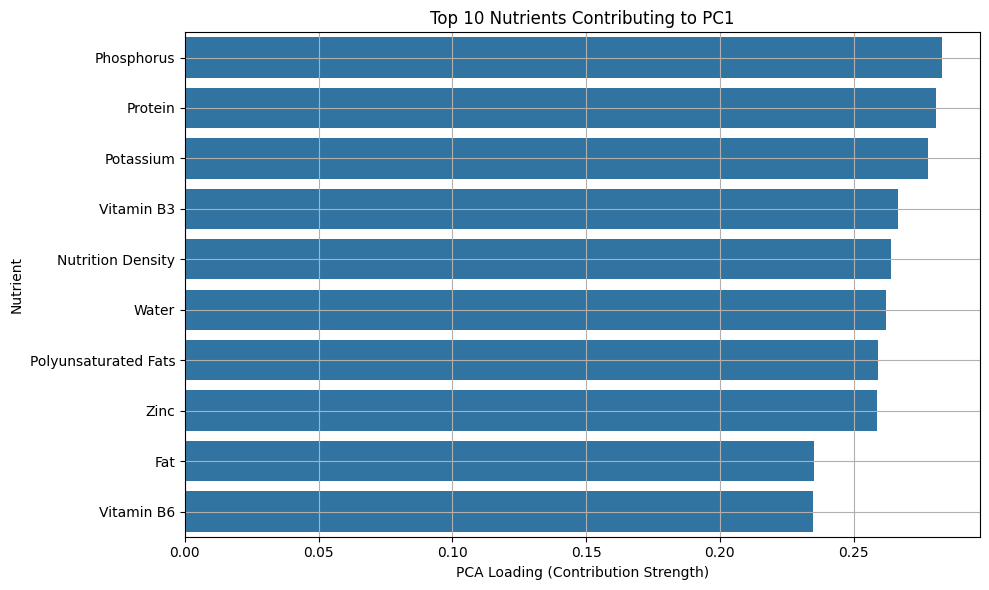

In [20]:
plt.figure(figsize=(10, 6))
sns.barplot(x=pca_loadings.head(10).values, y=pca_loadings.head(10).index)
plt.title("Top 10 Nutrients Contributing to PC1")
plt.xlabel("PCA Loading (Contribution Strength)")
plt.ylabel("Nutrient")
plt.grid(True)
plt.tight_layout()
plt.show()

These nutrients are the most influential in shaping the pattern of caloric value across food. The bar plot shows which nutrients contribute most to PC1 (Principal Component 1). 

### PC1 vs. Caloric Correlation: A Key Difference
It's important to see how these PC1 findings differ from simply looking at which nutrients directly correlate with calories.
- When looked at direct correlation with caloric value, fats (like Fat, Polyunsaturated Fats, Monounsaturated Fats) showed the strongest individual links to calories.
- However, with PC1, **Phosphorus, Protein, and Potassium** have higher influences (loadings) than even fat.

This tells that PC1 isn't just about 'caloric density'. Instead, it's a more complex factor that represents a broader concept, perhaps 'nutritional completeness' or 'density' that includes many different macro and micronutrients.

# Step 7: SVR with GridSearch
- try different 'C' (penalty), 'epsilon' (tolerance), and 'kernel' (function type).
- To systematically find the best parameters for SVR that minimize prediction error (MSE).

In [21]:
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    'epsilon': [0.01, 0.1, 0.5, 1], # Epsilon for the insensitive zone where no penalty is given.
    'kernel': ['rbf', 'poly'] # 'rbf' (Radial Basis Function) and 'poly' (Polynomial) are common kernel types.
}

In [22]:
svr = SVR()
grid_search = GridSearchCV(svr, param_grid, cv=5, scoring='neg_mean_squared_error', verbose=2, n_jobs=-1)
# .ravel() is used to convert the target 'y_train_scaled' from a column to a 1D array.
grid_search.fit(X_train_pca, y_train_scaled.ravel())

Fitting 5 folds for each of 56 candidates, totalling 280 fits


GridSearchCV(cv=5, estimator=SVR(), n_jobs=-1,
             param_grid={'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
                         'epsilon': [0.01, 0.1, 0.5, 1],
                         'kernel': ['rbf', 'poly']},
             scoring='neg_mean_squared_error', verbose=2)

In [25]:
print("Best Parameters:", grid_search.best_params_)
print("Best Score (Negative MSE):", grid_search.best_score_)
#Best parameters help train the most accurate model.
#Lower -MSE = better

Best Parameters: {'C': 100, 'epsilon': 0.1, 'kernel': 'rbf'}
Best Score (Negative MSE): -0.19587487877215906


### Finding the Best SVR Model
- (GridSearchCV) to find the ideal settings for SVR model.
- The best settings found were: 'C': 100, 'epsilon': 0.1, and 'kernel': 'rbf'.
- These settings gave best average performance in tests, with an error (Mean Squared Error) of about **0.196**.

These Settings Mean
- A high 'C' value (100) and the 'rbf' kernel mean the model tries really hard to fit the training data.
- This is good for accuracy on the data it's seen, but it creates a risk: the model might "overfit."
- This means it learns too much from the specific training examples and might not work as well on new, unseen data.

# Evaluate model train & test set 

In [26]:
best_model = grid_search.best_estimator_

## Training Set (scaled)

In [21]:
y_pred_train = best_model.predict(X_train_pca)
train_mse = metrics.mean_squared_error(y_train_scaled, y_pred_train)
train_mae = metrics.mean_absolute_error(y_train_scaled, y_pred_train)
train_r2 = metrics.r2_score(y_train_scaled, y_pred_train)

print('Train MSE:', train_mse)
print('Train MAE:', train_mae)
print('Train RMSE', np.sqrt(train_mse))
print('Train R-Squared', train_r2)

Train MSE: 0.03613708990163897
Train MAE: 0.105418737582466
Train RMSE 0.19009757994682355
Train R-Squared 0.963862910098361


The metrics obtained on training set indicate show strong performance. A very low Mean Squared Error (0.036) and Mean Absolute Error (0.105), coupled with an R-Squared value of approximately 0.964, suggest that the model has learned the underlying patterns in the training data with high fidelity. **This indicates that the model is highly capable of explaining the variance in caloric values for the data it was trained on.**

## Testing Set (scaled)

In [22]:
y_pred_test = best_model.predict(X_test_pca)
test_mse = metrics.mean_squared_error(y_test_scaled, y_pred_test)
test_mae = metrics.mean_absolute_error(y_test_scaled, y_pred_test)
test_r2 = metrics.r2_score(y_test_scaled, y_pred_test)

print('Test MSE:', test_mse)
print('Test MAE:', test_mae)
print('Test RMSE', np.sqrt(test_mse))
print('Test R-Squared', test_r2)

Test MSE: 0.1406365583162757
Test MAE: 0.1757771763206655
Test RMSE 0.37501541077171174
Test R-Squared 0.811716195828613


### A Clear Sign of Overfitting
The model achieved an R-squared of about 0.812 on new, unseen food items. This means it can explain roughly 81.2% of the variation in caloric value, which is generally a good sign of strong predictive ability.

However, the issue is the notable drop in R-squared from the training set's 0.964 to the testing set's 0.812. This large performance gap strongly indicates overfitting. The model likely learned specific details or "noise" from the training data that don't apply to new data, rather than truly generalizable patterns.

# Visual Performance Comparison
Bar charts to compare model performance

## MSE

In [23]:
data_accuracy = {'Train MSE': [train_mse], 'Test MSE': [test_mse]}

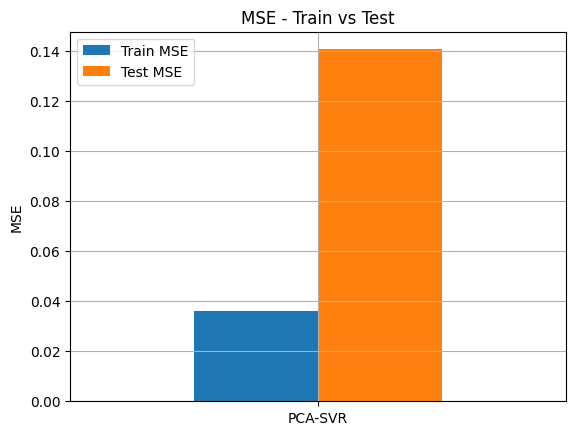

In [24]:
df_mse = pd.DataFrame(data_accuracy, index=['PCA-SVR'])
df_mse.plot.bar(rot=0)
plt.title('MSE - Train vs Test')
plt.ylabel('MSE')
plt.grid(True)
plt.show()

## R-Squared

In [25]:
data_accuracy_r2 = {'Train R2': [train_r2], 'Test R2': [test_r2]}

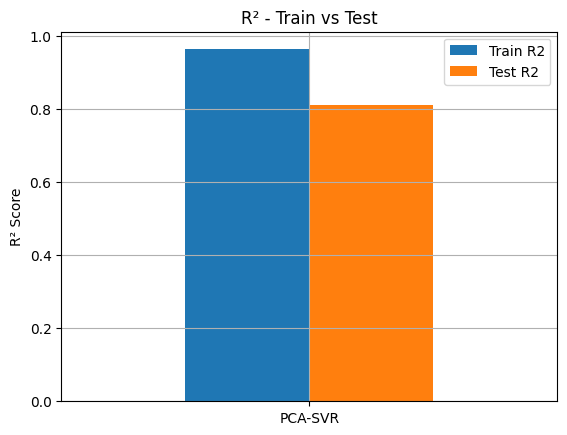

In [26]:
df_r2 = pd.DataFrame(data_accuracy_r2, index=['PCA-SVR'])
df_r2.plot.bar(rot=0)
plt.title('R² - Train vs Test')
plt.ylabel('R² Score')
plt.grid(True)
plt.show()